# Cybersecurity Threat Severity and Impact Classification
## Proyecto de Aula — Modelos y Simulación de Sistemas II
**Departamento de Ingeniería de Sistemas — Universidad de Antioquia**
**Autores:** Luis Carlos Vanegas Zapata, Alejandra Cano Espinosa, Robinson Dario Henao Botero

| Sección del informe | Contenido en el notebook | Tablas / figuras |
|---|---|---|
| I. Descripción del problema (A, B, C) | Sección I: contexto, datos, EDA, variable objetivo, codificación | Figura E1, Figura E2, Tabla E1 |
| III.1.1.A Metodología de validación y balance | Sección 1.1.A | — |
| III.1.1.B Malla de hiperparámetros (5 familias) | Sección 1.1.B | Tabla 1 |
| III.1.1.C Métricas | Sección 1.1.C | — |
| III.1.2 Resultados (train, validación y test con IC) | Sección 1.2 | Figura 1, Tablas 1B y 2, Figura 2, Figura P, Tablas 3 y 3B, Figura 3 |
| IV.2.1 Análisis individual de variables | Sección 2.1 | Tabla 4, Figura 4 |
| IV.2.2 Extracción lineal (PCA) | Sección 2.2 | Figura 5, Tabla 5 |
| IV.2.3.A Extracción no lineal (UMAP) | Sección 2.3.A | Figura 6, Tabla 6 |
| IV.2.3.B Discusión y conclusiones | Sección 2.3.B | Figura 7, Tabla 7 |

In [1]:
# Entorno. En local, instalar las versiones fijadas: pip install -r requirements.txt
#%pip install -r requirements.txt
%pip install -q imbalanced-learn umap-learn kagglehub
import os, glob, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV, ParameterGrid,
                                     cross_validate, cross_val_predict, permutation_test_score)
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score, roc_auc_score, recall_score, confusion_matrix
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.exceptions import ConvergenceWarning
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from umap import UMAP

for w in (FutureWarning, UserWarning, ConvergenceWarning):   # solo avisos conocidos (pandas/umap/MLP), no todos
    warnings.filterwarnings('ignore', category=w)
SEED, N_BOOT, N_PERM = 42, 1000, 1000
CLASSES = ['Low', 'Medium', 'High']
sns.set_theme(style='whitegrid', palette='muted')
for d in ('figuras', 'tablas'):
    os.makedirs(d, exist_ok=True)
save = lambda name: plt.savefig(f'figuras/{name}.png', dpi=200, bbox_inches='tight')
fmt = lambda c: f'{c[0]:.4f} [{c[1]:.4f}, {c[2]:.4f}]'      # media [IC 95 %]

/home/acene/.cache/uv/builds-v0/.tmpcqDdr4/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


# I. Descripción del problema

**A. Contexto.** Triaje automático de incidentes de ciberseguridad: dado un incidente en el momento de su detección ($t=0$), predecir su severidad $Y \in \{\text{Low}, \text{Medium}, \text{High}\}$ para priorizar la respuesta del equipo de seguridad.

**B. Base de datos.** *Global Cybersecurity Threats 2015-2024* (Kaggle): incidentes con país, año, tipo de ataque, sector, usuarios afectados, fuente del ataque, tipo de vulnerabilidad, mecanismo de defensa, pérdida financiera y tiempo de resolución. Se describen dimensiones, tipos, datos faltantes y duplicados.

In [2]:
def load_data(manual='data/Global_Cybersecurity_Threats_2015-2024.csv'):
    """Descarga con kagglehub; si no es posible, usa la copia local."""
    try:
        import kagglehub
        path = glob.glob(os.path.join(kagglehub.dataset_download('atharvasoundankar/global-cybersecurity-threats-2015-2024'), '*.csv'))[0]
    except Exception as e:
        print(f'kagglehub no disponible ({type(e).__name__}); se usa {manual}')
        path = manual
    return pd.read_csv(path).rename(columns=str.strip)

df = load_data()
LOSS, TIME = 'Financial Loss (in Million $)', 'Incident Resolution Time (in Hours)'
NUM = ['Year', 'Number of Affected Users']
CAT = ['Country', 'Attack Type', 'Target Industry', 'Attack Source', 'Security Vulnerability Type', 'Defense Mechanism Used']

print(f'N = {df.shape[0]} muestras, {df.shape[1]} variables | duplicados: {df.duplicated().sum()} | nulos: {df.isnull().sum().sum()}')
tabla_e1 = pd.DataFrame({'Tipo': df.dtypes.astype(str), 'Nulos': df.isnull().sum(), 'Niveles / únicos': df.nunique()})
display(tabla_e1, df[[LOSS, 'Number of Affected Users', TIME, 'Year']].describe().T.round(2))

100%|████████████████████████| 47.0k/47.0k [00:00<00:00, 222kB/s]

Extracting files...
N = 3000 muestras, 10 variables | duplicados: 0 | nulos: 0


,Tipo,Nulos,Niveles / únicos
Country,str,0,10
Year,int64,0,10
Attack Type,str,0,6
Target Industry,str,0,7
Financial Loss (in Million $),float64,0,2536
Number of Affected Users,int64,0,2998
Attack Source,str,0,4
Security Vulnerability Type,str,0,4
Defense Mechanism Used,str,0,5
Incident Resolution Time (in Hours),int64,0,72


,count,mean,std,min,25%,50%,75%,max
Financial Loss (in Million $),3000.0,50.49,28.79,0.5,25.76,50.8,75.63,99.99
Number of Affected Users,3000.0,504684.14,289944.08,424.0,255805.25,504513.0,758088.50,999635.00
Incident Resolution Time (in Hours),3000.0,36.48,20.57,1.0,19.00,37.0,55.00,72.00
Year,3000.0,2019.57,2.86,2015.0,2017.00,2020.0,2022.00,2024.00


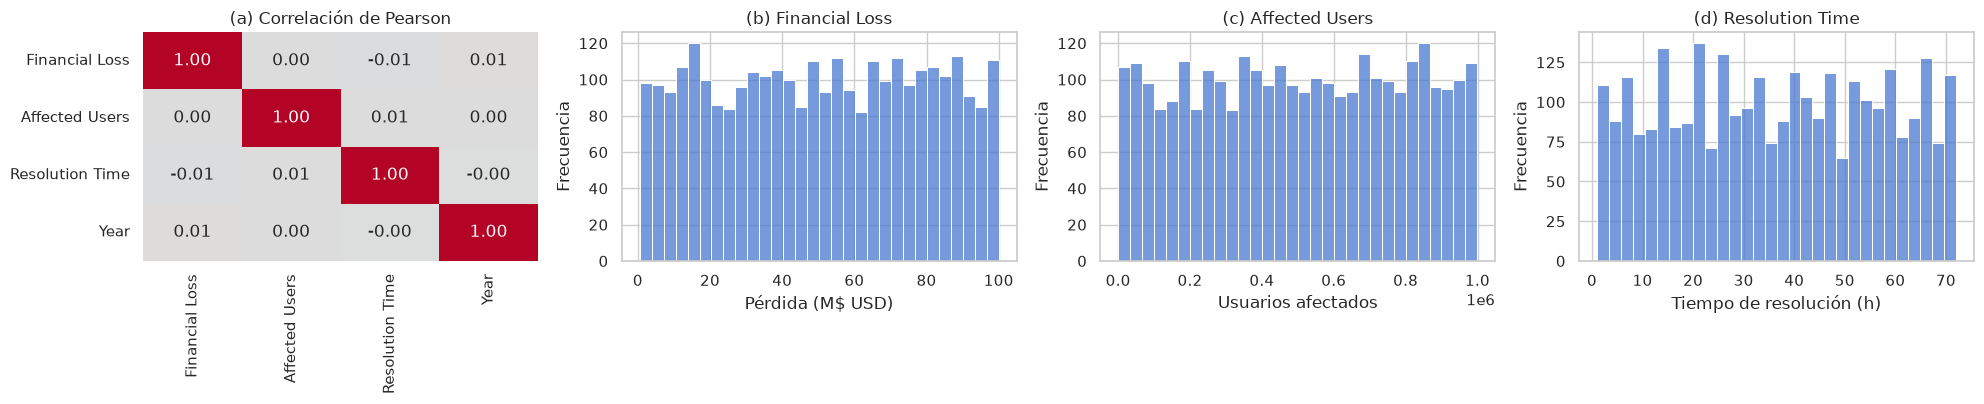

Máximo |r| fuera de la diagonal: 0.0127


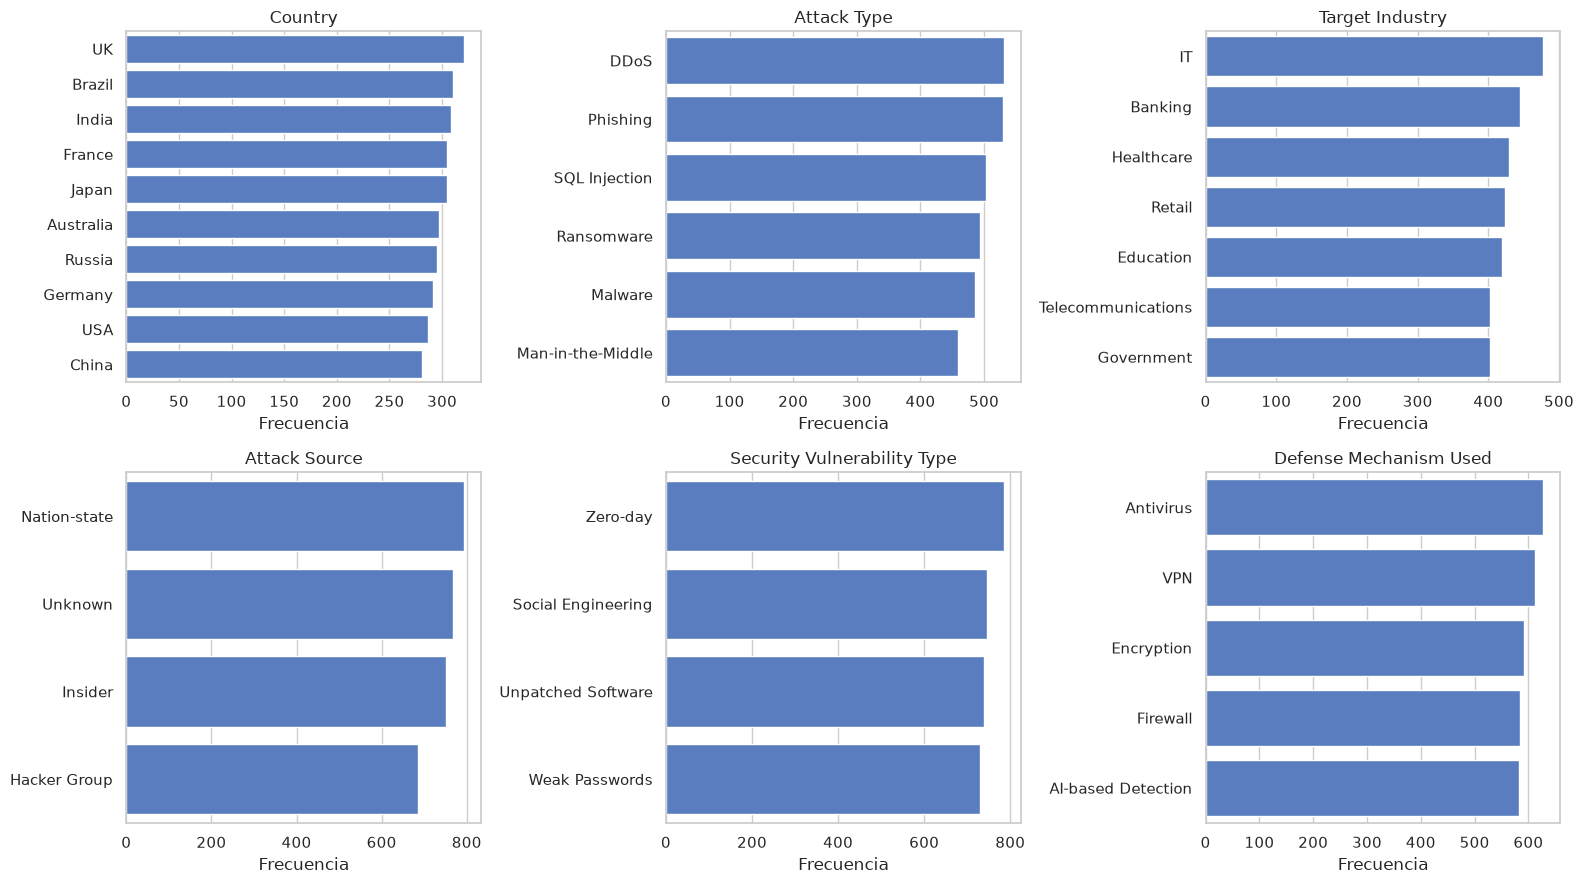

In [3]:
# Figura E1: correlación de Pearson e histogramas de las variables numéricas
short = {LOSS: 'Financial Loss', 'Number of Affected Users': 'Affected Users', TIME: 'Resolution Time', 'Year': 'Year'}
corr = df[list(short)].corr().rename(index=short, columns=short)
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, cbar=False, ax=axes[0])
axes[0].set_title('(a) Correlación de Pearson')
for ax, (col, xl), l in zip(axes[1:], [(LOSS, 'Pérdida (M$ USD)'), ('Number of Affected Users', 'Usuarios afectados'),
                                        (TIME, 'Tiempo de resolución (h)')], 'bcd'):
    sns.histplot(df[col], bins=30, ax=ax)
    ax.set(xlabel=xl, ylabel='Frecuencia', title=f'({l}) {short[col]}')
plt.tight_layout(); save('fig_E1_eda'); plt.show()
print(f'Máximo |r| fuera de la diagonal: {corr.abs().values[~np.eye(len(corr), dtype=bool)].max():.4f}')

# Figura E2: frecuencia de los niveles de cada variable categórica
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, CAT):
    sns.countplot(y=col, data=df, order=df[col].value_counts().index, ax=ax)
    ax.set(xlabel='Frecuencia', ylabel='', title=col)
plt.tight_layout(); save('fig_E2_categoricas'); plt.show()

### Variable objetivo, restricción anti-fuga y codificación

**Construcción de `Severity`.** No existe en el dataset: se define como los terciles (`pd.qcut`, $q=3$) del índice $\text{Impact} = \tfrac12\left[\text{rank}_{pct}(\text{Financial Loss}) + \text{rank}_{pct}(\text{Resolution Time})\right]$. Los rangos percentiles ponen ambas variables en la misma escala y dan igual peso a cada una; los terciles producen tres clases del mismo tamaño.

**Anti-fuga.** `Financial Loss`, `Resolution Time` e `Impact_Score` definen $Y$ y solo se conocen después de resolver el incidente, por lo que se excluyen de $X$. Se usan las 8 variables disponibles en $t=0$.

**Evidencia de origen sintético.** Se contrasta si las variables se comportan como uniformes e independientes: KS para `Financial Loss` (continua), $\chi^2$ de uniformidad para `Resolution Time` (entera, 1–72) y para los niveles de cada categórica, y $\chi^2$ de independencia entre cada categórica y `Severity`.

In [4]:
df['Impact_Score'] = (df[LOSS].rank(pct=True) + df[TIME].rank(pct=True)) / 2
df['Severity'] = pd.qcut(df['Impact_Score'], q=3, labels=CLASSES)

def diagnose_balance(y, name):
    """IR = max(n_k)/min(n_k). BALANCEADO si IR <= 1.5 y |p_k - 1/K| <= 0.05 para toda clase."""
    n = pd.Series(y).value_counts().sort_index()
    ir, ok = n.max() / n.min(), bool(n.max() / n.min() <= 1.5 and (n / n.sum() - 1 / len(n)).abs().max() <= 0.05)
    print(f"{name:28}: {n.tolist()} | IR = {ir:.2f} → {'BALANCEADO' if ok else 'DESBALANCEADO'}")
    return ir, ok

diagnose_balance(df['Severity'], 'Severity (dataset completo)')

fl, rt = df[LOSS], df[TIME]
print(f'DE Financial Loss = {fl.std():.2f} vs U(0.5, 100) = {99.5 / np.sqrt(12):.2f} | '
      f'DE Resolution Time = {rt.std():.2f} vs U{{1..72}} = {np.sqrt((72**2 - 1) / 12):.2f}')
pruebas = {'Financial Loss ~ Uniforme (KS)': stats.kstest(fl, 'uniform', args=(fl.min(), fl.max() - fl.min())).pvalue,
           'Resolution Time ~ U{1..72} (χ²)': stats.chisquare(rt.value_counts().reindex(range(1, 73), fill_value=0)).pvalue,
           **{f'{c}: niveles equiprobables (χ²)': stats.chisquare(df[c].value_counts()).pvalue for c in CAT},
           **{f'{c} ⟂ Severity (χ²)': stats.chi2_contingency(pd.crosstab(df[c], df['Severity']))[1] for c in CAT}}
display(pd.Series(pruebas, name='p-valor').round(3).to_frame())

Severity (dataset completo) : [1000, 1000, 1000] | IR = 1.00 → BALANCEADO
DE Financial Loss = 28.79 vs U(0.5, 100) = 28.72 | DE Resolution Time = 20.57 vs U{1..72} = 20.78


,p-valor
Financial Loss ~ Uniforme (KS),0.804
Resolution Time ~ U{1..72} (χ²),0.274
Country: niveles equiprobables (χ²),0.888
Attack Type: niveles equiprobables (χ²),0.184
Target Industry: niveles equiprobables (χ²),0.139
Attack Source: niveles equiprobables (χ²),0.037
Security Vulnerability Type: niveles equiprobables (χ²),0.499
Defense Mechanism Used: niveles equiprobables (χ²),0.643
Country ⟂ Severity (χ²),0.336
Attack Type ⟂ Severity (χ²),0.928


**Imputación, codificación y partición.** Todo el preprocesamiento vive en un único `ColumnTransformer` que se ajusta **solo con datos de entrenamiento** (dentro de cada pliegue en validación cruzada):
- Numéricas (`Year`, `Number of Affected Users`): imputación por mediana + estandarización Z-score.
- Categóricas nominales (6 variables): imputación por moda + One-Hot con `drop='first'` (evita la trampa de variables ficticias) → $D = 32$ columnas.
- Partición *holdout* estratificada 80/20 (`random_state=42`); el conjunto de prueba queda sellado hasta la evaluación final. Clases: `Low`=0, `Medium`=1, `High`=2.

**C. Paradigma.** Aprendizaje supervisado, clasificación multiclase (3 clases ordenadas de severidad).

In [5]:
X = df[NUM + CAT]
y = df['Severity'].cat.codes.values                      # Low=0, Medium=1, High=2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=df['Severity'], random_state=SEED)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_pre():
    num = SkPipeline([('imp', SimpleImputer(strategy='median')), ('z', StandardScaler())])
    cat = SkPipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(drop='first', sparse_output=False))])
    return ColumnTransformer([('num', num, NUM), ('cat', cat, CAT)], verbose_feature_names_out=False)

FEATURES = make_pre().fit(X_train).get_feature_names_out()
D = len(FEATURES)
print(f'Entrenamiento: {len(X_train)} | Prueba: {len(X_test)} | D = {D} características tras One-Hot')
for name, yy in [('y_train', y_train), ('y_test', y_test)] + \
                [(f'Pliegue {i} (train / val)', y_train[tr]) for i, (tr, _) in enumerate(CV.split(X_train, y_train), 1)]:
    diagnose_balance(yy, name)

Entrenamiento: 2400 | Prueba: 600 | D = 32 características tras One-Hot
y_train                     : [800, 800, 800] | IR = 1.00 → BALANCEADO
y_test                      : [200, 200, 200] | IR = 1.00 → BALANCEADO
Pliegue 1 (train / val)     : [640, 640, 640] | IR = 1.00 → BALANCEADO
Pliegue 2 (train / val)     : [640, 640, 640] | IR = 1.00 → BALANCEADO
Pliegue 3 (train / val)     : [640, 640, 640] | IR = 1.00 → BALANCEADO
Pliegue 4 (train / val)     : [640, 640, 640] | IR = 1.00 → BALANCEADO
Pliegue 5 (train / val)     : [640, 640, 640] | IR = 1.00 → BALANCEADO


**Conclusiones del EDA.** Sin datos faltantes ni duplicados; variables numéricas aproximadamente uniformes y sin correlación lineal entre sí; niveles categóricos casi equiprobables; ninguna variable categórica muestra dependencia con la severidad. El patrón es coherente con datos generados sintéticamente y anticipa poca señal predictiva en $t=0$. La severidad construida por terciles queda balanceada por construcción.

---
# III. Entrenamiento y evaluación de modelos

## 1.1 Configuración experimental

### 1.1.A Metodología de validación y gestión del balance
1. **Holdout estratificado 80/20**: 2 400 muestras de entrenamiento y 600 de prueba; la prueba no interviene en ninguna decisión.
2. **Validación cruzada estratificada $K=5$** sobre el entrenamiento (1 920 / 480 por pliegue) para toda decisión: hiperparámetros, dos mejores modelos y número de componentes de PCA y UMAP. Los mismos pliegues (`random_state=42`) se usan en todos los modelos.
3. **Pipeline anti-fuga**: imputación, codificación, estandarización, re-muestreo (si aplica) y reducción de dimensión se ajustan solo en el pliegue de entrenamiento (`imblearn.pipeline.Pipeline`).
4. **Intervalos de confianza**: en validación, $\bar x \pm t_{0.975,K-1}\, s/\sqrt K$ ($t_{0.975,4}\approx 2.776$); en prueba, bootstrap percentil con $B=1000$ réplicas de las 600 predicciones.
5. **Selección**: hiperparámetros y dos mejores modelos por **F1-macro medio de validación**.
6. **Balance**: diagnóstico con la razón de desbalance $IR$; si el entrenamiento está balanceado, `BALANCE_STRATEGY='none'`; si no, `class_weight='balanced'` en LR, RF y SVM y `RandomOverSampler` en KNN y MLP, siempre dentro del pliegue. Como el balance es nativo (IR = 1), su efecto se demuestra con una prueba de estrés de IR = 5 (Tabla 3B).

In [6]:
_, TRAIN_BALANCED = diagnose_balance(y_train, 'y_train')
BALANCE_STRATEGY = 'none' if TRAIN_BALANCED else 'class_weight'
SUPPORTS_CW = {'LogisticRegression', 'RandomForest', 'SVM'}
print(f'BALANCE_STRATEGY = {BALANCE_STRATEGY!r}')

def make_pipe(clf, sampler=None, reducer=None):
    """preprocesamiento → (re-muestreo) → (reducción) → clasificador; todo se ajusta solo en entrenamiento."""
    steps = [('pre', make_pre()), ('smp', sampler), ('red', reducer), ('clf', clf)]
    return Pipeline([s for s in steps if s[1] is not None])

def balanced_pipe(name, clf, reducer=None):
    if BALANCE_STRATEGY == 'none':
        return make_pipe(clf, reducer=reducer)
    if name in SUPPORTS_CW:
        return make_pipe(clf.set_params(class_weight='balanced'), reducer=reducer)
    return make_pipe(clf, RandomOverSampler(random_state=SEED), reducer)

y_train                     : [800, 800, 800] | IR = 1.00 → BALANCEADO
BALANCE_STRATEGY = 'none'


### 1.1.B Malla de hiperparámetros (Tabla 1)
Cinco familias exigidas por la guía: paramétrica (regresión logística), no paramétrica (KNN), ensamble de árboles (Random Forest), red neuronal (MLP) y máquina de vectores de soporte (SVM). Las escalas de regularización se exploran en malla logarítmica. La Tabla 1 se genera desde `MODELS`, por lo que coincide con lo ejecutado.

In [7]:
MODELS = {
    'LogisticRegression': (LogisticRegression(max_iter=1000, random_state=SEED), {'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}),
    'KNN':                (KNeighborsClassifier(weights='distance'), {'n_neighbors': [3, 5, 7, 11, 15, 21, 31, 45]}),
    'RandomForest':       (RandomForestClassifier(random_state=SEED), {'n_estimators': [50, 100, 200], 'max_depth': [5, 10, 15, None]}),
    'MLP':                (MLPClassifier(max_iter=500, random_state=SEED),
                           {'hidden_layer_sizes': [(32,), (64,), (64, 32), (100,)], 'alpha': [1e-4, 1e-3, 1e-2, 1e-1]}),
    'SVM':                (SVC(probability=True, random_state=SEED),
                           [{'kernel': ['linear'], 'C': [0.1, 1.0, 10.0]}, {'kernel': ['rbf'], 'C': [0.1, 1.0, 10.0], 'gamma': ['scale', 0.01]}]),
}
FAMILY = {'LogisticRegression': 'Paramétrico (regresión logística, L2)', 'KNN': 'No paramétrico (vecinos, ponderación por distancia)',
          'RandomForest': 'Ensamble de árboles (bagging)', 'MLP': 'Red neuronal artificial (ReLU, Adam)', 'SVM': 'Máquina de vectores de soporte'}
tabla1 = pd.DataFrame([{'Modelo': m, 'Familia': FAMILY[m], 'Malla de valores': str(g), 'N° combinaciones': len(ParameterGrid(g))}
                       for m, (_, g) in MODELS.items()])
display(tabla1)
print('Total de configuraciones:', tabla1['N° combinaciones'].sum())

,Modelo,Familia,Malla de valores,N° combinaciones
0,LogisticRegression,"Paramétrico (regresión logística, L2)","{'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}",6
1,KNN,"No paramétrico (vecinos, ponderación por dista...","{'n_neighbors': [3, 5, 7, 11, 15, 21, 31, 45]}",8
2,RandomForest,Ensamble de árboles (bagging),"{'n_estimators': [50, 100, 200], 'max_depth': ...",12
3,MLP,"Red neuronal artificial (ReLU, Adam)","{'hidden_layer_sizes': [(32,), (64,), (64, 32)...",16
4,SVM,Máquina de vectores de soporte,"[{'kernel': ['linear'], 'C': [0.1, 1.0, 10.0]}...",9


Total de configuraciones: 51


### 1.1.C Métricas de desempeño
- **F1-macro** (métrica de selección): $\frac13\sum_k F1_k$; pondera igual las tres severidades, de modo que ninguna clase oculta errores en las demás.
- **Exactitud (accuracy)**: proporción global de aciertos; fácil de interpretar.
- **Exactitud balanceada**: $\frac13\sum_k \text{Recall}_k$; sigue siendo válida si las clases se desbalancean (prueba de estrés). Con clases iguales coincide con la exactitud.
- **ROC-AUC macro (one-vs-rest)**: mide la capacidad de ordenar los incidentes por probabilidad, independiente del umbral; 0.5 equivale al azar.

**Línea base**: con 3 clases equilibradas, un clasificador aleatorio tiene F1-macro y exactitud esperadas de $1/3$. Los IC al 95 % permiten verificar si cada modelo supera ese valor; además se compara con un `DummyClassifier` estratificado y con una prueba de permutación.

In [8]:
SCORING = {'f1_macro': 'f1_macro', 'accuracy': 'accuracy', 'balanced_accuracy': 'balanced_accuracy', 'roc_auc': 'roc_auc_ovr'}

def t_ci(v):
    """Media e IC 95 % con t de Student (K pliegues)."""
    v = np.asarray(v, float)
    h = stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
    return v.mean(), v.mean() - h, v.mean() + h

def boot_ci(y, pred, proba, B=N_BOOT, seed=SEED):
    """Valor en prueba e IC 95 % bootstrap percentil para cada métrica."""
    idx = np.random.RandomState(seed).randint(0, len(y), (B, len(y)))
    fns = {'f1_macro': lambda i: f1_score(y[i], pred[i], average='macro'), 'accuracy': lambda i: accuracy_score(y[i], pred[i]),
           'balanced_accuracy': lambda i: balanced_accuracy_score(y[i], pred[i]),
           'roc_auc': lambda i: roc_auc_score(y[i], proba[i], multi_class='ovr')}
    return {k: (fn(np.arange(len(y))), *np.percentile([fn(i) for i in idx], [2.5, 97.5])) for k, fn in fns.items()}

def summarize(cv, fitted):
    """cv: puntajes por pliegue ('train_<m>', 'test_<m>'); fitted: modelo reajustado en todo el entrenamiento."""
    pred = fitted.predict(X_test)
    return {'train': {m: t_ci(cv[f'train_{m}']) for m in SCORING}, 'val': {m: t_ci(cv[f'test_{m}']) for m in SCORING},
            'test': boot_ci(y_test, pred, fitted.predict_proba(X_test)), 'pred': pred, 'model': fitted, 'cv': cv}

def run(pipe):
    """Validación cruzada K=5 + reajuste en todo el entrenamiento + evaluación única en prueba."""
    cv = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, return_train_score=True, return_estimator=True, n_jobs=-1)
    return summarize(cv, clone(pipe).fit(X_train, y_train))

## 1.2 Resultados del entrenamiento de modelos
Búsqueda en malla con `GridSearchCV` (mismos pliegues, F1-macro como criterio de `refit`). El mejor modelo de cada familia se reajusta en las 2 400 muestras de entrenamiento y se evalúa una sola vez en la prueba.

In [9]:
R, rows = {}, []
for name, (clf, grid) in MODELS.items():
    grid = [{f'clf__{k}': v for k, v in g.items()} for g in (grid if isinstance(grid, list) else [grid])]
    gs = GridSearchCV(balanced_pipe(name, clf), grid, cv=CV, scoring=SCORING, refit='f1_macro',
                      return_train_score=True, n_jobs=-1).fit(X_train, y_train)
    res = gs.cv_results_
    splits = lambda i, kind, m: [res[f'split{k}_{kind}_{m}'][i] for k in range(CV.n_splits)]
    for i, p in enumerate(res['params']):
        rows.append({'Modelo': name, **{k[5:]: v for k, v in p.items()}, 'Train F1': np.mean(splits(i, 'train', 'f1_macro')),
                     **dict(zip(['Val F1', 'IC inf', 'IC sup'], t_ci(splits(i, 'test', 'f1_macro'))))})
    i = gs.best_index_
    R[name] = summarize({f'{kd}_{m}': splits(i, kd, m) for kd in ('train', 'test') for m in SCORING}, gs.best_estimator_)
    R[name]['params'] = {k[5:]: v for k, v in gs.best_params_.items()}
    print(f"{name:18} {str(R[name]['params']):55} Val F1 {fmt(R[name]['val']['f1_macro'])} | Test F1 {fmt(R[name]['test']['f1_macro'])}")
grid_df = pd.DataFrame(rows)

LogisticRegression {'C': 0.01}                                             Val F1 0.3334 [0.3004, 0.3665] | Test F1 0.3582 [0.3238, 0.3971]
KNN                {'n_neighbors': 45}                                     Val F1 0.3364 [0.3157, 0.3571] | Test F1 0.3586 [0.3228, 0.3948]
RandomForest       {'max_depth': 15, 'n_estimators': 200}                  Val F1 0.3403 [0.3161, 0.3645] | Test F1 0.3450 [0.3065, 0.3844]
MLP                {'alpha': 0.1, 'hidden_layer_sizes': (64, 32)}          Val F1 0.3319 [0.3145, 0.3494] | Test F1 0.3143 [0.2764, 0.3511]
SVM                {'C': 1.0, 'gamma': 'scale', 'kernel': 'rbf'}           Val F1 0.3357 [0.3129, 0.3585] | Test F1 0.3438 [0.3053, 0.3830]


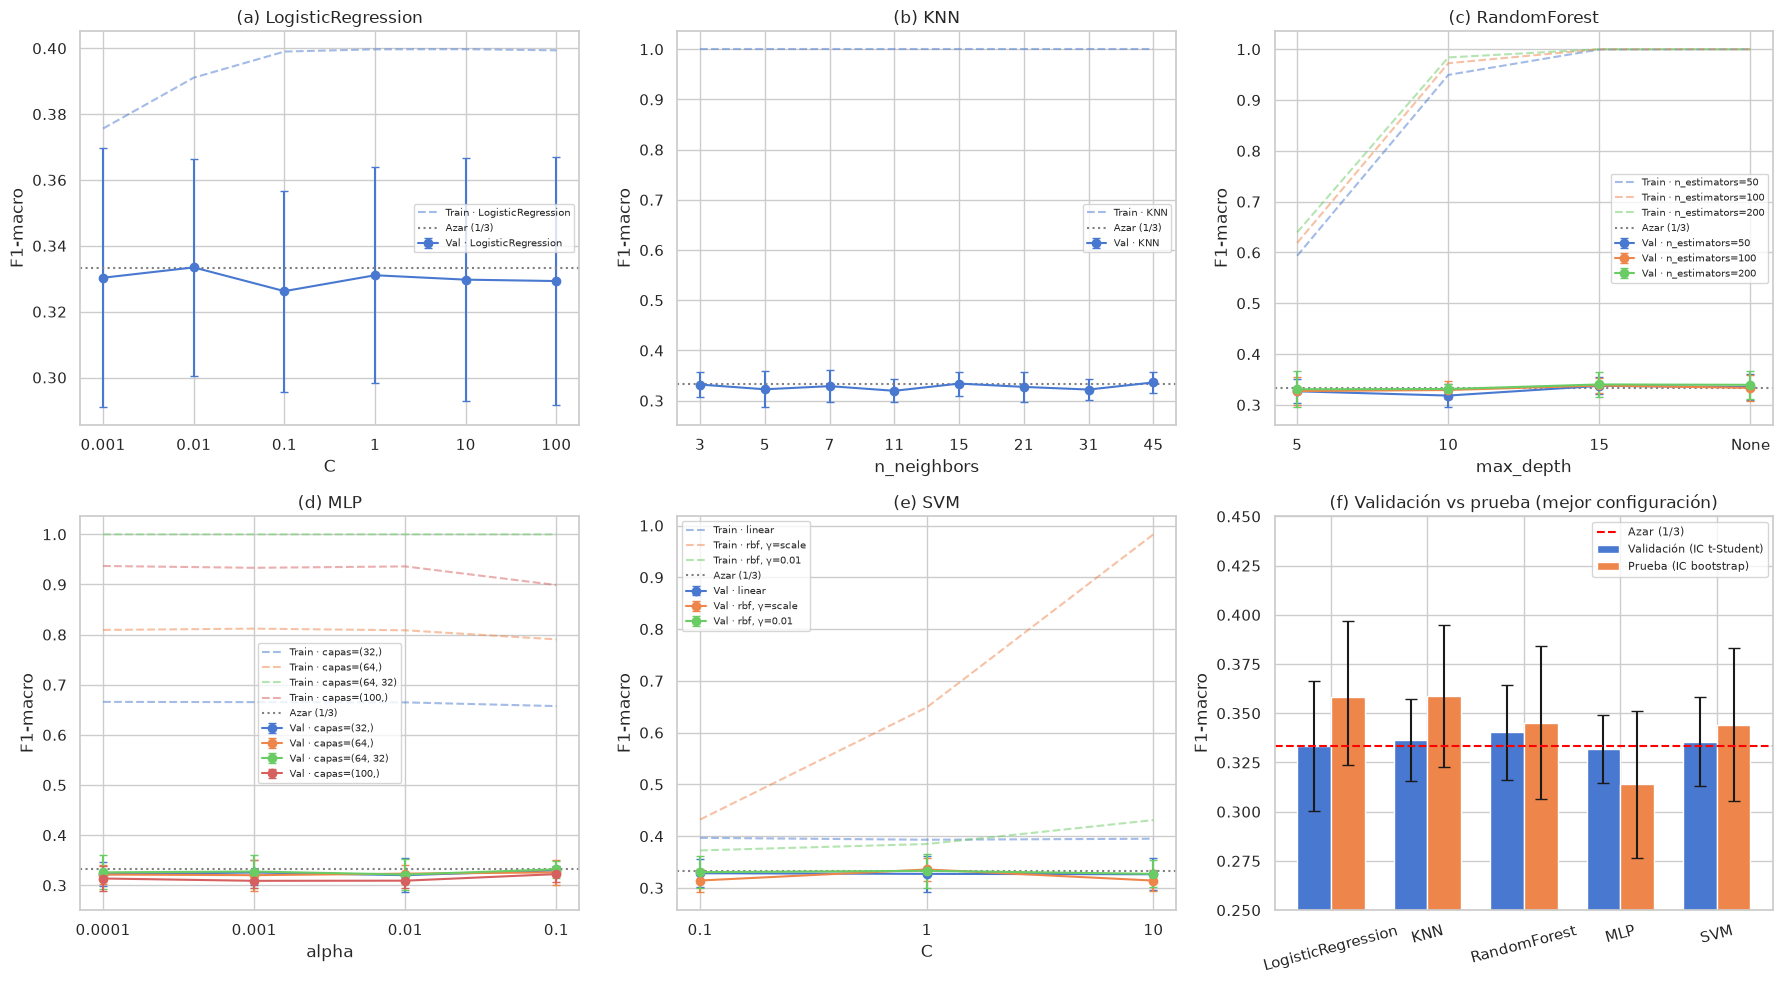

,Modelo,C,Train F1,Val F1,IC inf,IC sup,n_neighbors,max_depth,n_estimators,alpha,hidden_layer_sizes,kernel,gamma
0,LogisticRegression,0.001,0.3756,0.3303,0.2910,0.3696,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,LogisticRegression,0.010,0.3911,0.3334,0.3004,0.3665,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,LogisticRegression,0.100,0.3990,0.3262,0.2957,0.3567,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LogisticRegression,1.000,0.3997,0.3311,0.2982,0.3639,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,LogisticRegression,10.000,0.3997,0.3297,0.2927,0.3667,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,LogisticRegression,100.000,0.3994,0.3293,0.2915,0.3671,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,KNN,NaN,1.0000,0.3321,0.3069,0.3573,3.0,NaN,NaN,NaN,NaN,NaN,NaN
7,KNN,NaN,1.0000,0.3227,0.2871,0.3583,5.0,NaN,NaN,NaN,NaN,NaN,NaN
8,KNN,NaN,1.0000,0.3290,0.2966,0.3614,7.0,NaN,NaN,NaN,NaN,NaN,NaN
9,KNN,NaN,1.0000,0.3197,0.2971,0.3423,11.0,NaN,NaN,NaN,NaN,NaN,NaN


Train F1        Val F1       
                        min    max    min    max
Modelo                                          
KNN                   1.000  1.000  0.320  0.336
LogisticRegression    0.376  0.400  0.326  0.333
MLP                   0.657  1.000  0.309  0.332
RandomForest          0.594  1.000  0.318  0.340
SVM                   0.372  0.983  0.314  0.336

In [10]:
# Figura 1: efecto de los hiperparámetros (train y validación con IC 95 %) y comparación validación vs prueba
lab = lambda v: 'None' if v is None or (isinstance(v, float) and np.isnan(v)) else (f'{v:g}' if isinstance(v, (int, float)) else str(v))
def hue(r):
    if r.Modelo == 'RandomForest': return f'n_estimators={r.n_estimators:.0f}'
    if r.Modelo == 'MLP': return f'capas={r.hidden_layer_sizes}'
    if r.Modelo == 'SVM': return 'linear' if r.kernel == 'linear' else f'rbf, γ={r.gamma}'
    return r.Modelo
PANEL_X = {'LogisticRegression': 'C', 'KNN': 'n_neighbors', 'RandomForest': 'max_depth', 'MLP': 'alpha', 'SVM': 'C'}
grid_df['Configuración'] = grid_df.apply(hue, axis=1)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (m, xcol), l in zip(axes.flat, PANEL_X.items(), 'abcde'):
    sub = grid_df[grid_df.Modelo == m].assign(x=lambda d: d[xcol].map(lab))
    order = list(dict.fromkeys(sub.x))
    for (h, g), c in zip(sub.groupby('Configuración', sort=False), sns.color_palette(n_colors=4)):
        pos = g.x.map(order.index)
        ax.errorbar(pos, g['Val F1'], yerr=g['IC sup'] - g['Val F1'], fmt='o-', color=c, capsize=3, label=f'Val · {h}')
        ax.plot(pos, g['Train F1'], '--', color=c, alpha=0.5, label=f'Train · {h}')
    ax.axhline(1/3, color='gray', ls=':', label='Azar (1/3)')
    ax.set(xticks=range(len(order)), xticklabels=order, xlabel=xcol, ylabel='F1-macro', title=f'({l}) {m}')
    ax.legend(fontsize=7)
names = list(R)
val = np.array([R[m]['val']['f1_macro'] for m in names]); tst = np.array([R[m]['test']['f1_macro'] for m in names])
x = np.arange(len(names))
axes[1, 2].bar(x - 0.175, val[:, 0], 0.35, yerr=val[:, 2] - val[:, 0], capsize=4, label='Validación (IC t-Student)')
axes[1, 2].bar(x + 0.175, tst[:, 0], 0.35, yerr=[tst[:, 0] - tst[:, 1], tst[:, 2] - tst[:, 0]], capsize=4, label='Prueba (IC bootstrap)')
axes[1, 2].axhline(1/3, color='red', ls='--', label='Azar (1/3)')
axes[1, 2].set(xticks=x, xticklabels=names, ylim=(0.25, 0.45), ylabel='F1-macro', title='(f) Validación vs prueba (mejor configuración)')
axes[1, 2].tick_params(axis='x', rotation=15); axes[1, 2].legend(fontsize=8)
plt.tight_layout(); save('fig1_hiperparametros'); plt.show()

# Tabla 1B: las configuraciones de la malla
display(grid_df.drop(columns='Configuración').round(4))
display(grid_df.groupby('Modelo')[['Train F1', 'Val F1']].agg(['min', 'max']).round(3))

In [11]:
# Tabla 2: desempeño en entrenamiento, validación (IC t) y prueba (IC bootstrap); ranking por F1 de validación
ORDER = sorted(R, key=lambda m: -R[m]['val']['f1_macro'][0])
TOP2 = ORDER[:2]
tabla2 = pd.DataFrame({m: {'Hiperparámetros': R[m]['params'], 'Train F1': round(R[m]['train']['f1_macro'][0], 4),
                           'Brecha train−val': round(R[m]['train']['f1_macro'][0] - R[m]['val']['f1_macro'][0], 4),
                           **{f'Val {k}': fmt(R[m]['val'][k]) for k in SCORING}, **{f'Test {k}': fmt(R[m]['test'][k]) for k in SCORING}}
                       for m in ORDER}).T
display(tabla2)
print('Dos mejores modelos (solo por validación):', TOP2)

,Hiperparámetros,Train F1,Brecha train−val,Val f1_macro,Val accuracy,Val balanced_accuracy,Val roc_auc,Test f1_macro,Test accuracy,Test balanced_accuracy,Test roc_auc
RandomForest,"{'max_depth': 15, 'n_estimators': 200}",1.0,0.6597,"0.3403 [0.3161, 0.3645]","0.3408 [0.3169, 0.3648]","0.3408 [0.3169, 0.3648]","0.4946 [0.4848, 0.5044]","0.3450 [0.3065, 0.3844]","0.3450 [0.3067, 0.3850]","0.3450 [0.3079, 0.3847]","0.5043 [0.4687, 0.5405]"
KNN,{'n_neighbors': 45},1.0,0.6636,"0.3364 [0.3157, 0.3571]","0.3375 [0.3162, 0.3588]","0.3375 [0.3162, 0.3588]","0.4921 [0.4719, 0.5124]","0.3586 [0.3228, 0.3948]","0.3583 [0.3233, 0.3950]","0.3583 [0.3228, 0.3958]","0.5251 [0.4940, 0.5595]"
SVM,"{'C': 1.0, 'gamma': 'scale', 'kernel': 'rbf'}",0.6487,0.3131,"0.3357 [0.3129, 0.3585]","0.3362 [0.3132, 0.3593]","0.3362 [0.3132, 0.3593]","0.4847 [0.4694, 0.5000]","0.3438 [0.3053, 0.3830]","0.3433 [0.3050, 0.3833]","0.3433 [0.3046, 0.3829]","0.4932 [0.4606, 0.5267]"
LogisticRegression,{'C': 0.01},0.3911,0.0576,"0.3334 [0.3004, 0.3665]","0.3346 [0.3013, 0.3678]","0.3346 [0.3013, 0.3678]","0.4966 [0.4654, 0.5278]","0.3582 [0.3238, 0.3971]","0.3617 [0.3267, 0.4017]","0.3617 [0.3270, 0.4014]","0.5157 [0.4832, 0.5501]"
MLP,"{'alpha': 0.1, 'hidden_layer_sizes': (64, 32)}",0.9999,0.668,"0.3319 [0.3145, 0.3494]","0.3321 [0.3149, 0.3493]","0.3321 [0.3149, 0.3493]","0.4931 [0.4729, 0.5133]","0.3143 [0.2764, 0.3511]","0.3150 [0.2767, 0.3517]","0.3150 [0.2770, 0.3527]","0.4877 [0.4560, 0.5186]"


Dos mejores modelos (solo por validación): ['RandomForest', 'KNN']


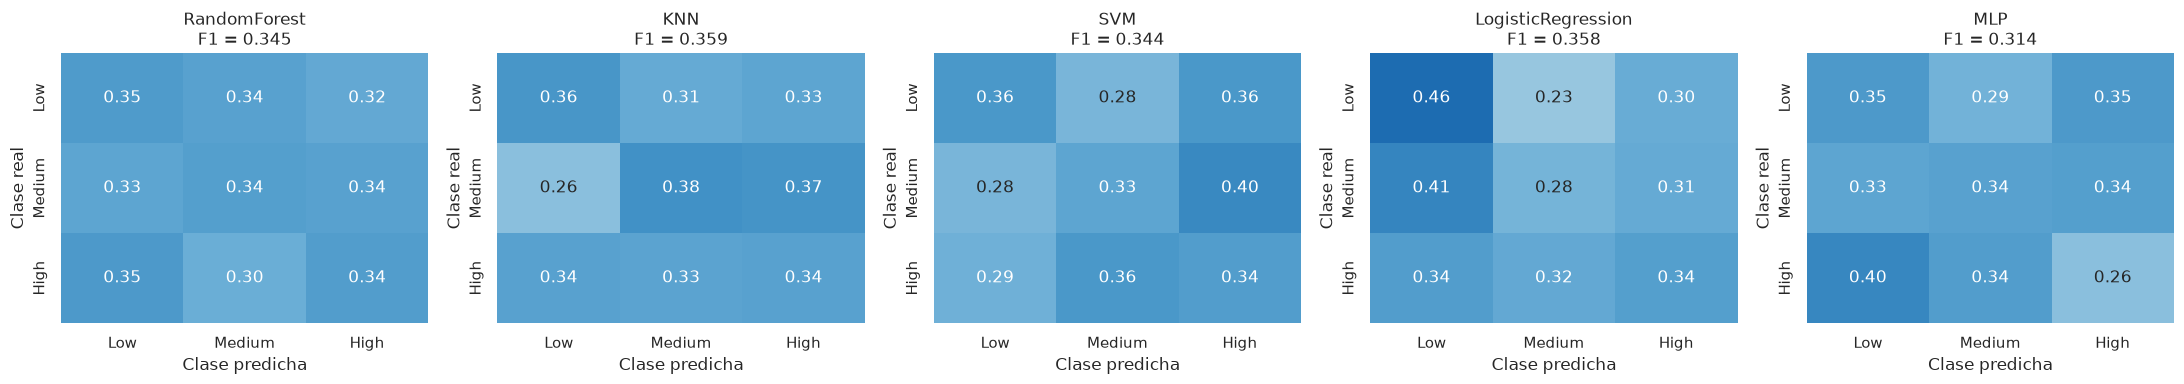

,Pred. Low,Pred. Medium,Pred. High
RandomForest,206,195,199
KNN,191,203,206
SVM,187,193,220
LogisticRegression,242,167,191
MLP,216,194,190


In [12]:
# Figura 2: matrices de confusión normalizadas por fila en prueba + distribución de predicciones
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, m in zip(axes, ORDER):
    sns.heatmap(confusion_matrix(y_test, R[m]['pred'], normalize='true'), annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=0.6,
                cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set(title=f"{m}\nF1 = {R[m]['test']['f1_macro'][0]:.3f}", xlabel='Clase predicha', ylabel='Clase real')
plt.tight_layout(); save('fig2_confusion'); plt.show()
display(pd.DataFrame({m: np.bincount(R[m]['pred'], minlength=3) for m in ORDER}, index=[f'Pred. {c}' for c in CLASSES]).T)

,IC val incluye 1/3,IC test incluye 1/3,Δ F1 test vs dummy
RandomForest,True,True,-0.0132
KNN,True,True,0.0004
SVM,True,True,-0.0144
LogisticRegression,True,True,0.0001
MLP,True,True,-0.0438


Dummy estratificado — Test F1 0.3582 [0.3183, 0.3962]
Permutación (RandomForest): F1 observado = 0.3403 | H0: 0.3334 ± 0.0114 | p = 0.2667


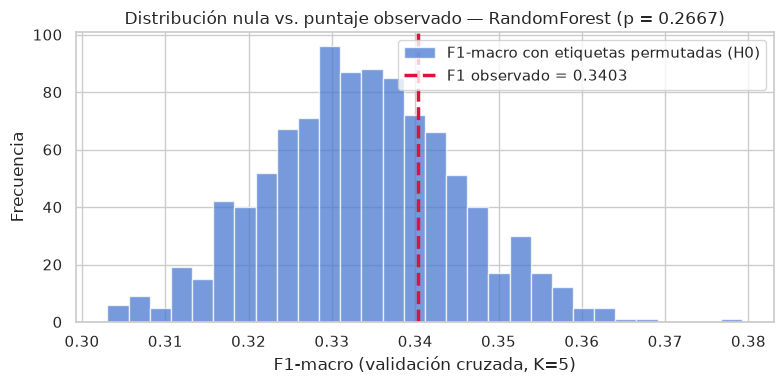

In [13]:
# Comparación con el azar: IC vs 1/3, DummyClassifier estratificado y prueba de permutación (Figura P)
dummy = make_pipe(DummyClassifier(strategy='stratified', random_state=SEED)).fit(X_train, y_train)
dummy_test = boot_ci(y_test, dummy.predict(X_test), dummy.predict_proba(X_test))
inside = lambda c: c[1] <= 1/3 <= c[2]
display(pd.DataFrame({m: {'IC val incluye 1/3': inside(R[m]['val']['f1_macro']), 'IC test incluye 1/3': inside(R[m]['test']['f1_macro']),
                          'Δ F1 test vs dummy': round(R[m]['test']['f1_macro'][0] - dummy_test['f1_macro'][0], 4)} for m in ORDER}).T)
print(f"Dummy estratificado — Test F1 {fmt(dummy_test['f1_macro'])}")

best = ORDER[0]
score, perm, p_value = permutation_test_score(clone(R[best]['model']), X_train, y_train, cv=CV, scoring='f1_macro',
                                              n_permutations=N_PERM, random_state=SEED, n_jobs=-1)
print(f'Permutación ({best}): F1 observado = {score:.4f} | H0: {perm.mean():.4f} ± {perm.std():.4f} | p = {p_value:.4f}')
plt.figure(figsize=(8, 4))
plt.hist(perm, bins=30, alpha=0.75, label='F1-macro con etiquetas permutadas (H0)')
plt.axvline(score, color='crimson', ls='--', lw=2.5, label=f'F1 observado = {score:.4f}')
plt.xlabel('F1-macro (validación cruzada, K=5)'); plt.ylabel('Frecuencia')
plt.title(f'Distribución nula vs. puntaje observado — {best} (p = {p_value:.4f})'); plt.legend()
plt.tight_layout(); save('figP_permutacion'); plt.show()

### Gestión del balance: sensibilidad (Tabla 3) y prueba de estrés (Tabla 3B, Figura 3)
Con los hiperparámetros óptimos se comparan `none`, `class_weight='balanced'` (LR, RF, SVM), `RandomOverSampler` y `RandomUnderSampler`, aplicados solo en el pliegue de entrenamiento. Se reportan F1-macro y exactitud balanceada (IC $t$) y el recall por clase sobre las predicciones fuera de pliegue: (a) sobre el entrenamiento real (IR = 1) y (b) sobre un subconjunto con desbalance artificial 800/400/160 (IR = 5). La prueba no se usa.

Subconjunto de estrés       : [800, 400, 160] | IR = 5.00 → DESBALANCEADO
Tabla 3 — entrenamiento real (IR = 1)


,Modelo,Estrategia,F1,BalAcc,Recall Low,Recall Medium,Recall High,% pred. High
0,RandomForest,none,"0.3403 [0.3161, 0.3645]","0.3408 [0.3169, 0.3648]",0.349,0.348,0.326,32.208
1,RandomForest,class_weight,"0.3393 [0.3178, 0.3607]","0.3396 [0.3183, 0.3609]",0.342,0.345,0.331,32.917
2,RandomForest,random_oversample,"0.3403 [0.3161, 0.3645]","0.3408 [0.3169, 0.3648]",0.349,0.348,0.326,32.208
3,RandomForest,random_undersample,"0.3420 [0.3229, 0.3610]","0.3421 [0.3228, 0.3614]",0.360,0.338,0.329,33.625
4,KNN,none,"0.3364 [0.3157, 0.3571]","0.3375 [0.3162, 0.3588]",0.331,0.364,0.318,33.417
5,KNN,random_oversample,"0.3364 [0.3157, 0.3571]","0.3375 [0.3162, 0.3588]",0.331,0.364,0.318,33.417
6,KNN,random_undersample,"0.3364 [0.3157, 0.3571]","0.3375 [0.3162, 0.3588]",0.331,0.364,0.318,33.417
7,SVM,none,"0.3357 [0.3129, 0.3585]","0.3362 [0.3132, 0.3593]",0.322,0.336,0.350,34.750
8,SVM,class_weight,"0.3357 [0.3129, 0.3585]","0.3362 [0.3132, 0.3593]",0.322,0.336,0.350,34.750
9,SVM,random_oversample,"0.3357 [0.3129, 0.3585]","0.3362 [0.3132, 0.3593]",0.322,0.336,0.350,34.750


Tabla 3B — prueba de estrés (IR = 5)


,Modelo,Estrategia,F1,BalAcc,Recall Low,Recall Medium,Recall High,% pred. High
0,RandomForest,none,"0.2896 [0.2740, 0.3052]","0.3387 [0.3288, 0.3487]",0.926,0.078,0.012,0.294
1,RandomForest,class_weight,"0.3272 [0.3053, 0.3492]","0.3317 [0.3092, 0.3542]",0.665,0.268,0.062,6.397
2,RandomForest,random_oversample,"0.3134 [0.2976, 0.3291]","0.3296 [0.3142, 0.3449]",0.776,0.175,0.038,3.824
3,RandomForest,random_undersample,"0.2989 [0.2827, 0.3151]","0.3192 [0.2954, 0.3430]",0.359,0.318,0.281,29.412
4,KNN,none,"0.2552 [0.2466, 0.2639]","0.3337 [0.3288, 0.3387]",0.986,0.015,0.000,0.000
5,KNN,random_oversample,"0.2896 [0.2511, 0.3282]","0.3167 [0.2793, 0.3541]",0.314,0.342,0.294,33.235
6,KNN,random_undersample,"0.3184 [0.2988, 0.3380]","0.3425 [0.3044, 0.3806]",0.356,0.390,0.281,29.412
7,SVM,none,"0.2575 [0.2444, 0.2705]","0.3358 [0.3278, 0.3439]",0.990,0.018,0.000,0.000
8,SVM,class_weight,"0.3275 [0.3144, 0.3406]","0.3350 [0.3183, 0.3517]",0.472,0.332,0.200,18.971
9,SVM,random_oversample,"0.3340 [0.3149, 0.3530]","0.3354 [0.3165, 0.3543]",0.569,0.312,0.125,12.868


,Recall High,BalAcc
Estrategia,,
none,0.0200,0.3364
class_weight,0.2083,0.3360
random_oversample,0.1738,0.3292
random_undersample,0.3338,0.3368


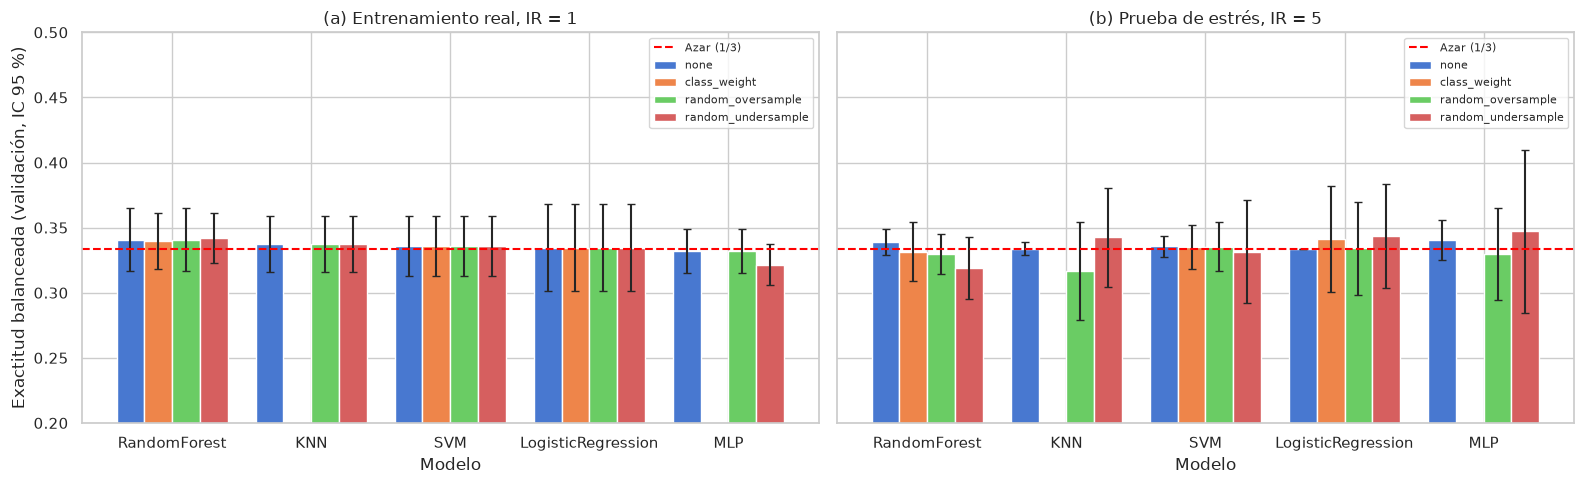

In [14]:
base_clf = lambda m: clone(R[m]['model'].named_steps['clf']).set_params(**({'class_weight': None} if m in SUPPORTS_CW else {}))
STRATEGIES = {'none':               lambda m: make_pipe(base_clf(m)),
              'class_weight':       lambda m: make_pipe(base_clf(m).set_params(class_weight='balanced')) if m in SUPPORTS_CW else None,
              'random_oversample':  lambda m: make_pipe(base_clf(m), RandomOverSampler(random_state=SEED)),
              'random_undersample': lambda m: make_pipe(base_clf(m), RandomUnderSampler(random_state=SEED))}

def balance_experiment(X, y):
    rows = []
    for m in ORDER:
        for s, build in STRATEGIES.items():
            if (pipe := build(m)) is None:
                continue
            oof = cross_val_predict(pipe, X, y, cv=CV, n_jobs=-1)          # predicciones fuera de pliegue
            folds = [(f1_score(y[va], oof[va], average='macro'), balanced_accuracy_score(y[va], oof[va])) for _, va in CV.split(X, y)]
            rows.append({'Modelo': m, 'Estrategia': s, 'F1': t_ci([f for f, _ in folds]), 'BalAcc': t_ci([b for _, b in folds]),
                         **dict(zip([f'Recall {c}' for c in CLASSES], recall_score(y, oof, average=None, labels=[0, 1, 2], zero_division=0))),
                         '% pred. High': 100 * np.mean(oof == 2)})
    return pd.DataFrame(rows)

rng = np.random.RandomState(SEED)
keep = np.sort(np.concatenate([rng.choice(np.flatnonzero(y_train == k), n, replace=False) for k, n in {0: 800, 1: 400, 2: 160}.items()]))
X_imb, y_imb = X_train.iloc[keep], y_train[keep]
diagnose_balance(y_imb, 'Subconjunto de estrés')
tabla3, tabla3b = balance_experiment(X_train, y_train), balance_experiment(X_imb, y_imb)
show = lambda t: t.assign(F1=t.F1.map(fmt), BalAcc=t.BalAcc.map(fmt)).round(3)
print('Tabla 3 — entrenamiento real (IR = 1)'); display(show(tabla3))
print('Tabla 3B — prueba de estrés (IR = 5)'); display(show(tabla3b))
display(tabla3b.assign(BalAcc=tabla3b.BalAcc.str[0]).groupby('Estrategia', sort=False)[['Recall High', 'BalAcc']].mean().round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, (t, title) in zip(axes, [(tabla3, '(a) Entrenamiento real, IR = 1'), (tabla3b, '(b) Prueba de estrés, IR = 5')]):
    t = t.assign(mean=t.BalAcc.str[0], err=t.BalAcc.map(lambda c: c[2] - c[0]))
    piv = lambda v: t.pivot(index='Modelo', columns='Estrategia', values=v).reindex(index=ORDER, columns=list(STRATEGIES))
    piv('mean').plot.bar(yerr=piv('err'), ax=ax, capsize=3, rot=0, width=0.8)
    ax.axhline(1/3, color='red', ls='--', label='Azar (1/3)')
    ax.set(ylim=(0.2, 0.5), xlabel='Modelo', ylabel='Exactitud balanceada (validación, IC 95 %)', title=title)
    ax.legend(fontsize=8)
plt.tight_layout(); save('fig3_balance'); plt.show()

---
# IV. Reducción de dimensión

## 2.1 Análisis individual de variables (Tabla 4, Figura 4)
Sobre el entrenamiento codificado ($D=32$) se calcula el estadístico **ANOVA $F$** (separación lineal de medias entre clases) y la **información mutua** (dependencia lineal o no lineal; *dummies* tratadas como discretas). Una variable es **candidata a eliminar** si $p_{\text{ANOVA}} > 0.15$ **y** $MI \le 0.005$ nats. Como se realizan 32 pruebas, se compara el número de significativas con el esperado por azar ($32 \times 0.15$) y se aplica la corrección de Bonferroni ($0.05/32$).

,ANOVA F,p-valor,MI (nats),Decisión
Country_India,2.8374,0.0588,0.0012,Conservar
Security Vulnerability Type_Unpatched Software,2.7729,0.0627,0.0012,Conservar
Attack Source_Insider,2.6083,0.0739,0.0011,Conservar
Security Vulnerability Type_Weak Passwords,2.2129,0.1096,0.0009,Conservar
Target Industry_Government,1.8738,0.1538,0.0008,Candidata a eliminar
Target Industry_Education,1.8726,0.1539,0.0008,Candidata a eliminar
Attack Type_Ransomware,1.7896,0.1673,0.0007,Candidata a eliminar
Defense Mechanism Used_Firewall,1.5925,0.2036,0.0007,Candidata a eliminar
Country_Brazil,1.2724,0.2803,0.0005,Candidata a eliminar
Number of Affected Users,1.2427,0.2888,0.0000,Candidata a eliminar


F crítico (p = 0.15; gl 2 y 2397) = 1.8986
Significativas con p ≤ 0.15: 4 observadas vs 4.8 esperadas por azar | tras Bonferroni (p ≤ 0.0016): 0
Candidatas a eliminar: 27 de 32 | Conservadas: ['Country_India', 'Security Vulnerability Type_Unpatched Software', 'Attack Source_Insider', 'Security Vulnerability Type_Weak Passwords', 'Year']


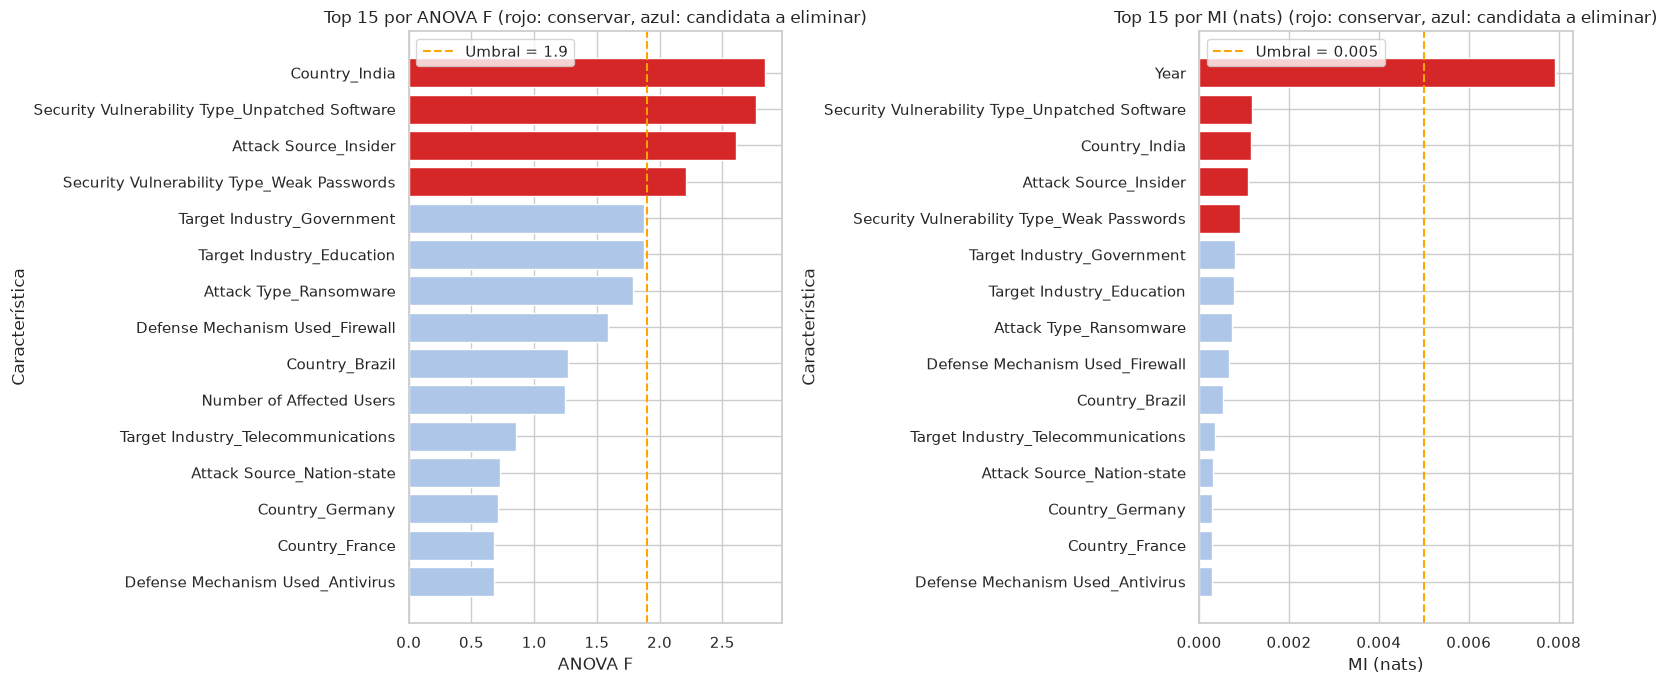

In [15]:
pre = make_pre().fit(X_train)
Xtr = pd.DataFrame(pre.transform(X_train), columns=FEATURES)
F, p = f_classif(Xtr, y_train)
mi = mutual_info_classif(Xtr, y_train, discrete_features=[f not in NUM for f in FEATURES], random_state=SEED)
tabla4 = pd.DataFrame({'ANOVA F': F, 'p-valor': p, 'MI (nats)': mi}, index=FEATURES).sort_values('ANOVA F', ascending=False)
tabla4['Decisión'] = np.where((tabla4['p-valor'] > 0.15) & (tabla4['MI (nats)'] <= 0.005), 'Candidata a eliminar', 'Conservar')
display(tabla4.round(4))
print(f"F crítico (p = 0.15; gl 2 y {len(y_train) - 3}) = {stats.f.ppf(0.85, 2, len(y_train) - 3):.4f}")
print(f"Significativas con p ≤ 0.15: {(tabla4['p-valor'] <= 0.15).sum()} observadas vs {D * 0.15:.1f} esperadas por azar | "
      f"tras Bonferroni (p ≤ {0.05 / D:.4f}): {(tabla4['p-valor'] <= 0.05 / D).sum()}")
print(f"Candidatas a eliminar: {(tabla4['Decisión'] != 'Conservar').sum()} de {D} | Conservadas: {tabla4.index[tabla4['Decisión'] == 'Conservar'].tolist()}")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, col, thr in zip(axes, ['ANOVA F', 'MI (nats)'], [stats.f.ppf(0.85, 2, len(y_train) - 3), 0.005]):
    top = tabla4.nlargest(15, col).iloc[::-1]
    ax.barh(top.index, top[col], color=np.where(top['Decisión'] == 'Conservar', '#d62728', '#aec7e8'))
    ax.axvline(thr, color='orange', ls='--', label=f'Umbral = {thr:.3g}')
    ax.set(xlabel=col, ylabel='Característica', title=f'Top 15 por {col} (rojo: conservar, azul: candidata a eliminar)')
    ax.legend()
plt.tight_layout(); save('fig4_variables'); plt.show()

## 2.2 Extracción lineal de características: PCA (Figura 5, Tabla 5)
**Criterio:** el menor número de componentes que retiene al menos el **90 % de la varianza** acumulada. En validación cruzada se usa `PCA(n_components=0.90)` dentro del pipeline, por lo que $K$ se determina en cada pliegue de entrenamiento; para la prueba, PCA se ajusta en todo el entrenamiento. Se reevalúan los dos mejores modelos con sus hiperparámetros óptimos.

K = 22 componentes (90.11% de varianza) → reducción del 31.25% | PC1 = 16.73%, PC1-3 = 37.80%


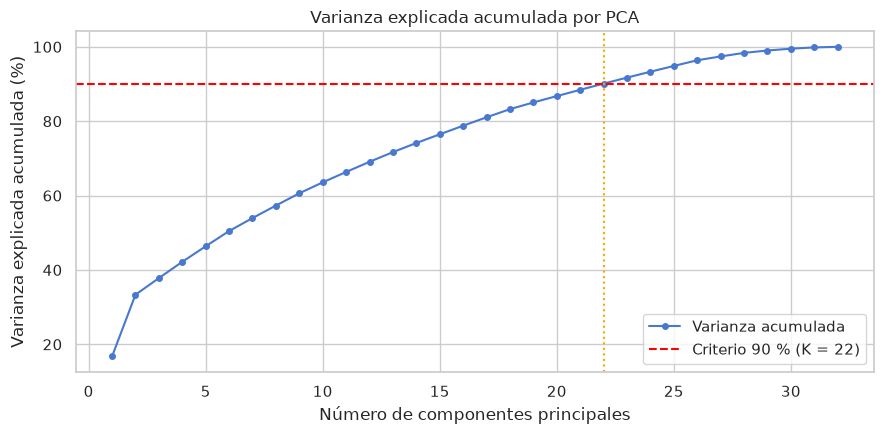

RandomForest: K por pliegue = [22, 22, 22, 22, 22] | K final (prueba) = 22
KNN: K por pliegue = [22, 22, 22, 22, 22] | K final (prueba) = 22


,Modelo,Espacio,% Reducción,Train F1,Val F1,Test F1,Test accuracy,Test balanced_accuracy,Test roc_auc,Pred. L/M/H
0,RandomForest,Original (32),0.0%,1.0,"0.3403 [0.3161, 0.3645]","0.3450 [0.3065, 0.3844]",0.3450,0.3450,0.5043,"[206, 195, 199]"
1,RandomForest,PCA (22),31.2%,1.0,"0.3325 [0.3252, 0.3397]","0.3400 [0.3017, 0.3802]",0.3400,0.3400,0.4907,"[196, 193, 211]"
2,KNN,Original (32),0.0%,1.0,"0.3364 [0.3157, 0.3571]","0.3586 [0.3228, 0.3948]",0.3583,0.3583,0.5251,"[191, 203, 206]"
3,KNN,PCA (22),31.2%,1.0,"0.3384 [0.3107, 0.3661]","0.3493 [0.3128, 0.3875]",0.3500,0.3500,0.5109,"[193, 211, 196]"


In [16]:
cum = np.cumsum(PCA(svd_solver='full').fit(Xtr).explained_variance_ratio_)
k_pca = int(np.argmax(cum >= 0.90) + 1)
print(f'K = {k_pca} componentes ({cum[k_pca - 1]:.2%} de varianza) → reducción del {1 - k_pca / D:.2%} | PC1 = {cum[0]:.2%}, PC1-3 = {cum[2]:.2%}')

plt.figure(figsize=(9, 4.5))
plt.plot(range(1, D + 1), cum * 100, 'o-', ms=4, label='Varianza acumulada')
plt.axhline(90, color='red', ls='--', label=f'Criterio 90 % (K = {k_pca})'); plt.axvline(k_pca, color='orange', ls=':')
plt.xlabel('Número de componentes principales'); plt.ylabel('Varianza explicada acumulada (%)')
plt.title('Varianza explicada acumulada por PCA'); plt.legend(); plt.tight_layout(); save('fig5_pca'); plt.show()

best_clf = lambda m: clone(R[m]['model'].named_steps['clf'])
RED = {(m, 'Original'): (R[m], D) for m in TOP2}
for m in TOP2:
    r = run(balanced_pipe(m, best_clf(m), PCA(n_components=0.90, svd_solver='full', random_state=SEED)))
    RED[(m, 'PCA')] = (r, int(r['model'].named_steps['red'].n_components_))
    print(f"{m}: K por pliegue = {[int(e.named_steps['red'].n_components_) for e in r['cv']['estimator']]} | K final (prueba) = {RED[(m, 'PCA')][1]}")

def red_table(spaces):
    keys = [(m, s) for m in TOP2 for s in ('Original', 'PCA', 'UMAP') if s in spaces and (m, s) in RED]
    return pd.DataFrame([{'Modelo': m, 'Espacio': f'{s} ({k})', '% Reducción': f'{1 - k / D:.1%}', 'Train F1': round(r['train']['f1_macro'][0], 4),
                          'Val F1': fmt(r['val']['f1_macro']), 'Test F1': fmt(r['test']['f1_macro']),
                          **{f'Test {n}': round(r['test'][n][0], 4) for n in ('accuracy', 'balanced_accuracy', 'roc_auc')},
                          'Pred. L/M/H': np.bincount(r['pred'], minlength=3).tolist()}
                         for (m, s), (r, k) in ((key, RED[key]) for key in keys)])

tabla5 = red_table({'Original', 'PCA'}); display(tabla5)

## 2.3.A Extracción no lineal de características: UMAP (Figura 6, Tabla 6)
**Criterio:** se evalúa $K \in \{2, 3, 5, 10, 15\}$ (`n_neighbors=15`, `min_dist=0.1`) con validación cruzada y UMAP dentro del pipeline. Por **parsimonia** se elige el menor $K$ cuyo F1 medio de validación alcanza el límite inferior del IC 95 % del mejor $K$; se adopta el menor $K$ admisible para ambos modelos (si no existe, el del mejor modelo).

,RandomForest,KNN
K,,
2,"0.3314 [0.3098, 0.3529]","0.3343 [0.3005, 0.3682]"
3,"0.3261 [0.2856, 0.3667]","0.3283 [0.2905, 0.3661]"
5,"0.3328 [0.3126, 0.3529]","0.3308 [0.3028, 0.3589]"
10,"0.3247 [0.2895, 0.3599]","0.3316 [0.2920, 0.3713]"
15,"0.3331 [0.3032, 0.3629]","0.3264 [0.2914, 0.3613]"


K admisibles: {'RandomForest': {2, 3, 5, 10, 15}, 'KNN': {2, 3, 5, 10, 15}} → K elegido = 2 (reducción del 93.75%)


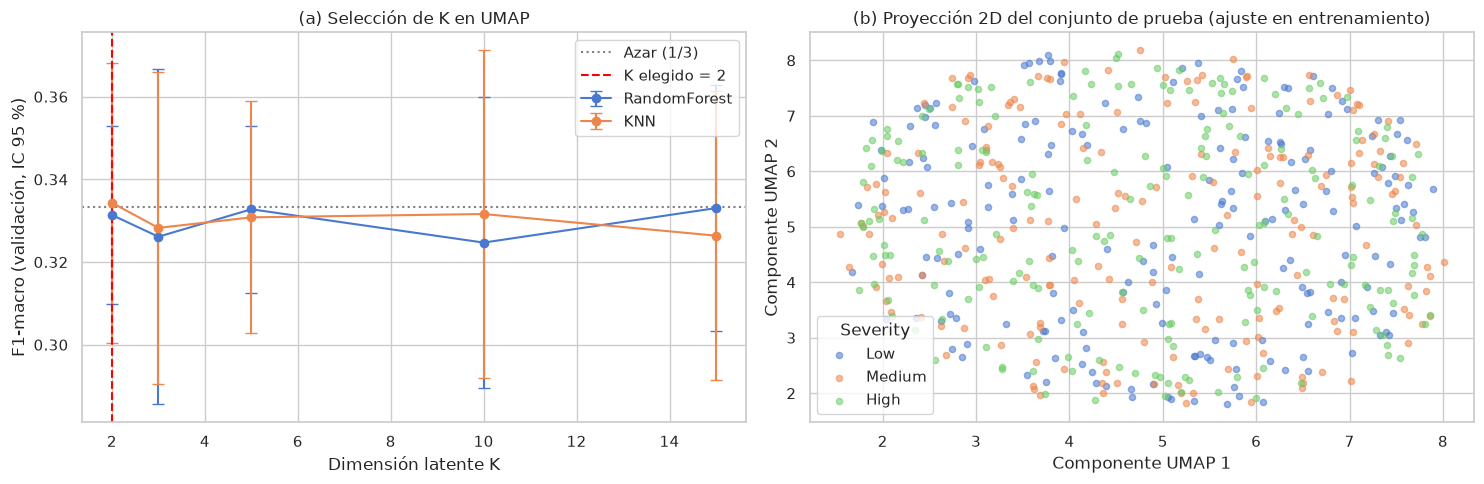

,Modelo,Espacio,% Reducción,Train F1,Val F1,Test F1,Test accuracy,Test balanced_accuracy,Test roc_auc,Pred. L/M/H
0,RandomForest,Original (32),0.0%,1.0,"0.3403 [0.3161, 0.3645]","0.3450 [0.3065, 0.3844]",0.3450,0.3450,0.5043,"[206, 195, 199]"
1,RandomForest,UMAP (2),93.8%,1.0,"0.3314 [0.3098, 0.3529]","0.3267 [0.2911, 0.3637]",0.3317,0.3317,0.5083,"[223, 241, 136]"
2,KNN,Original (32),0.0%,1.0,"0.3364 [0.3157, 0.3571]","0.3586 [0.3228, 0.3948]",0.3583,0.3583,0.5251,"[191, 203, 206]"
3,KNN,UMAP (2),93.8%,1.0,"0.3343 [0.3005, 0.3682]","0.3355 [0.2990, 0.3720]",0.3500,0.3500,0.5056,"[303, 192, 105]"


In [17]:
K_GRID = [2, 3, 5, 10, 15]
umap_pipe = lambda m, k: balanced_pipe(m, best_clf(m), UMAP(n_components=k, n_neighbors=15, min_dist=0.1, random_state=SEED))
ucv = {(m, k): t_ci(cross_validate(umap_pipe(m, k), X_train, y_train, cv=CV, scoring='f1_macro', n_jobs=-1)['test_score'])
       for m in TOP2 for k in K_GRID}
admissible = {m: {k for k in K_GRID if ucv[m, k][0] >= max((ucv[m, kk] for kk in K_GRID), key=lambda c: c[0])[1]} for m in TOP2}
common = set.intersection(*admissible.values())
k_umap = min(common) if common else min(admissible[TOP2[0]])
display(pd.DataFrame({m: {k: fmt(ucv[m, k]) for k in K_GRID} for m in TOP2}).rename_axis('K'))
print(f'K admisibles: {admissible} → K elegido = {k_umap} (reducción del {1 - k_umap / D:.2%})')

for m in TOP2:
    RED[(m, 'UMAP')] = (run(umap_pipe(m, k_umap)), k_umap)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for m in TOP2:
    c = np.array([ucv[m, k] for k in K_GRID])
    axes[0].errorbar(K_GRID, c[:, 0], yerr=c[:, 2] - c[:, 0], fmt='o-', capsize=4, label=m)
axes[0].axhline(1/3, color='gray', ls=':', label='Azar (1/3)'); axes[0].axvline(k_umap, color='red', ls='--', label=f'K elegido = {k_umap}')
axes[0].set(xlabel='Dimensión latente K', ylabel='F1-macro (validación, IC 95 %)', title='(a) Selección de K en UMAP'); axes[0].legend()
emb = SkPipeline([('pre', make_pre()), ('umap', UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=SEED))]).fit(X_train).transform(X_test)
for k, c in enumerate(CLASSES):
    axes[1].scatter(*emb[y_test == k].T, s=20, alpha=0.55, label=c)
axes[1].set(xlabel='Componente UMAP 1', ylabel='Componente UMAP 2', title='(b) Proyección 2D del conjunto de prueba (ajuste en entrenamiento)')
axes[1].legend(title='Severity'); plt.tight_layout(); save('fig6_umap'); plt.show()

tabla6 = red_table({'Original', 'UMAP'}); display(tabla6)

## 2.3.B Discusión y conclusiones (Figura 7, Tabla 7)
Se comparan los dos mejores modelos en los tres espacios. Dos espacios se consideran equivalentes si sus IC 95 % de validación se solapan; la recomendación final aplica el mismo criterio de parsimonia (menor dimensión cuyo F1 medio alcanza el límite inferior del IC del mejor espacio).

,Modelo,Espacio,% Reducción,Train F1,Val F1,Test F1,Test accuracy,Test balanced_accuracy,Test roc_auc,Pred. L/M/H
0,RandomForest,Original (32),0.0%,1.0,"0.3403 [0.3161, 0.3645]","0.3450 [0.3065, 0.3844]",0.3450,0.3450,0.5043,"[206, 195, 199]"
1,RandomForest,PCA (22),31.2%,1.0,"0.3325 [0.3252, 0.3397]","0.3400 [0.3017, 0.3802]",0.3400,0.3400,0.4907,"[196, 193, 211]"
2,RandomForest,UMAP (2),93.8%,1.0,"0.3314 [0.3098, 0.3529]","0.3267 [0.2911, 0.3637]",0.3317,0.3317,0.5083,"[223, 241, 136]"
3,KNN,Original (32),0.0%,1.0,"0.3364 [0.3157, 0.3571]","0.3586 [0.3228, 0.3948]",0.3583,0.3583,0.5251,"[191, 203, 206]"
4,KNN,PCA (22),31.2%,1.0,"0.3384 [0.3107, 0.3661]","0.3493 [0.3128, 0.3875]",0.3500,0.3500,0.5109,"[193, 211, 196]"
5,KNN,UMAP (2),93.8%,1.0,"0.3343 [0.3005, 0.3682]","0.3355 [0.2990, 0.3720]",0.3500,0.3500,0.5056,"[303, 192, 105]"


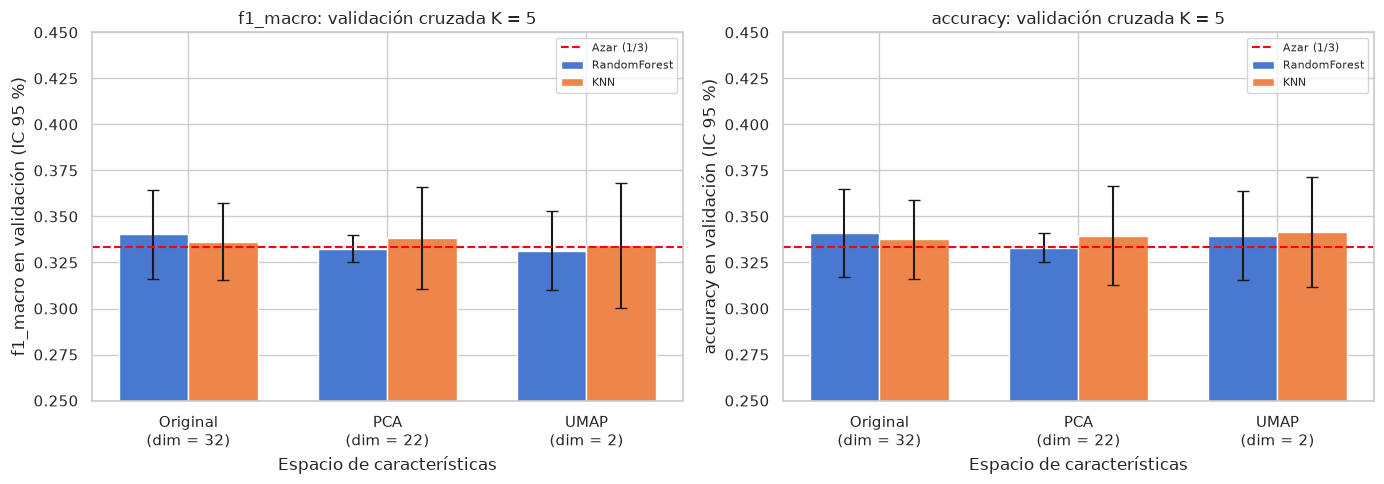

RandomForest       Original  dim=32 | Val F1 0.3403 [0.3161, 0.3645] | incluye 1/3: True | solapa con original: True
RandomForest       PCA       dim=22 | Val F1 0.3325 [0.3252, 0.3397] | incluye 1/3: True | solapa con original: True
RandomForest       UMAP      dim= 2 | Val F1 0.3314 [0.3098, 0.3529] | incluye 1/3: True | solapa con original: True
  → mejor espacio en validación: Original; recomendado por parsimonia: UMAP (dim = 2)
KNN                Original  dim=32 | Val F1 0.3364 [0.3157, 0.3571] | incluye 1/3: True | solapa con original: True
KNN                PCA       dim=22 | Val F1 0.3384 [0.3107, 0.3661] | incluye 1/3: True | solapa con original: True
KNN                UMAP      dim= 2 | Val F1 0.3343 [0.3005, 0.3682] | incluye 1/3: True | solapa con original: True
  → mejor espacio en validación: PCA; recomendado por parsimonia: UMAP (dim = 2)
Tablas exportadas en tablas/ y figuras en figuras/


In [18]:
tabla7 = red_table({'Original', 'PCA', 'UMAP'}); display(tabla7)

SPACES = ['Original', 'PCA', 'UMAP']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, met in zip(axes, ['f1_macro', 'accuracy']):
    for j, m in enumerate(TOP2):
        c = np.array([RED[(m, s)][0]['val'][met] for s in SPACES])
        ax.bar(np.arange(3) + (j - 0.5) * 0.35, c[:, 0], 0.35, yerr=c[:, 2] - c[:, 0], capsize=4, label=m)
    ax.axhline(1/3, color='red', ls='--', label='Azar (1/3)')
    ax.set(xticks=range(3), xticklabels=[f'{s}\n(dim = {RED[(TOP2[0], s)][1]})' for s in SPACES], ylim=(0.25, 0.45),
           xlabel='Espacio de características', ylabel=f'{met} en validación (IC 95 %)', title=f'{met}: validación cruzada K = 5')
    ax.legend(fontsize=8)
plt.tight_layout(); save('fig7_espacios'); plt.show()

for m in TOP2:
    o = RED[(m, 'Original')][0]['val']['f1_macro']
    cand = {s: (RED[(m, s)][1], RED[(m, s)][0]['val']['f1_macro']) for s in SPACES}
    for s, (k, v) in cand.items():
        print(f"{m:18} {s:9} dim={k:2d} | Val F1 {fmt(v)} | incluye 1/3: {inside(v)} | solapa con original: {not (o[2] < v[1] or v[2] < o[1])}")
    best_s = max(cand, key=lambda s: cand[s][1][0])
    pick = min((s for s in cand if cand[s][1][0] >= cand[best_s][1][1]), key=lambda s: cand[s][0])
    print(f'  → mejor espacio en validación: {best_s}; recomendado por parsimonia: {pick} (dim = {cand[pick][0]})')

for n, t in {'tabla1': tabla1, 'tabla1B': grid_df, 'tabla2': tabla2, 'tabla3': show(tabla3), 'tabla3B': show(tabla3b),
             'tabla4': tabla4, 'tabla5': tabla5, 'tabla6': tabla6, 'tabla7': tabla7}.items():
    t.to_csv(f'tablas/{n}.csv')
print('Tablas exportadas en tablas/ y figuras en figuras/')

### Conclusiones
- **Selección sin fuga hacia la prueba.** Hiperparámetros, los dos mejores modelos y el número de componentes de PCA y UMAP se eligieron solo con validación cruzada; todo el preprocesamiento (imputación, One-Hot, Z-score), el re-muestreo y la reducción de dimensión se ajustan dentro de cada pliegue de entrenamiento.
- **Desempeño frente al azar.** Interpretar las Tablas 2 y 7 junto con la línea base: si los IC incluyen $1/3$, el ROC-AUC es cercano a 0.5, el modelo apenas supera al `DummyClassifier` y la prueba de permutación no rechaza $H_0$, las 8 variables disponibles en $t=0$ no contienen señal útil para predecir la severidad. Esto es coherente con las pruebas del EDA (variables uniformes e independientes de la severidad, dataset probablemente sintético).
- **Sobreajuste.** Una brecha train−validación grande (F1 de entrenamiento cercano a 1) con validación cercana a $1/3$ indica memorización de ruido, no capacidad predictiva.
- **Balance.** Con IR = 1 las estrategias de balance no producen diferencias distinguibles (IC solapados): los pesos son unitarios y no hay muestras que duplicar; con IR = 5 recuperan el recall de la clase minoritaria, pero no aumentan la exactitud balanceada si no hay señal.
- **Reducción de dimensión.** Si los IC de PCA y UMAP se solapan con los del espacio original, se puede reducir la dimensión sin pérdida distinguible; con desempeño al nivel del azar esto refleja ausencia de señal, no que pocas componentes capturen la estructura de la severidad.
- **Limitaciones.** Con $K=5$ los IC $t$ son aproximados (los pliegues comparten datos); el bootstrap en prueba solo cuantifica la variabilidad de las 600 muestras; elegir el máximo entre 51 configuraciones introduce un sesgo optimista.